# Лабораторная работа №1. Метод k ближайших соседей (KNN)

**Цель:** провести исследование алгоритма KNN на задачах классификации и регрессии: выбрать данные и метрики, построить бейзлайн на `scikit-learn`, улучшить его проверкой гипотез, самостоятельно реализовать алгоритм и сравнить результаты.

Структура ноутбука повторяет пункты задания:
1. Выбор начальных условий (наборы данных, метрики).
2. Бейзлайн `sklearn` и оценка качества.
3. Улучшение бейзлайна: гипотезы → проверка на кросс-валидации → улучшенный бейзлайн → сравнение и выводы.
4. Собственная имплементация KNN: сравнение с бейзлайном, затем добавление техник улучшенного бейзлайна и сравнение с п. 3.

Перед каждой ячейкой с кодом есть текстовое пояснение, что и зачем в ней делается.

## 0. Подготовка окружения

Импортируем библиотеки и общий пакет `mllab` из корня репозитория. В `mllab` лежат:
загрузчики данных (`mllab.data`), генераторы признаков (`mllab.features`), функции подсчёта метрик и журнал результатов (`mllab.metrics`), а также собственные реализации алгоритмов (`mllab.knn`, `mllab.linear`, `mllab.tree`, `mllab.forest`, `mllab.boosting`).
Предупреждения отключаем, чтобы не засорять вывод; для `Pipeline` включаем дисковый кэш (`.cache/`), чтобы тяжёлые преобразования признаков не пересчитывались в каждом прогоне кросс-валидации.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Code, display
from joblib import Memory
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

import mllab
from mllab.data import RANDOM_STATE, load_chess, load_dota
from mllab.features import ChessFeatures, DotaFeatures
from mllab.metrics import ResultsLog, compare_cv, cv_report, evaluate

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 120)
memory = Memory(ROOT / ".cache", verbose=0)

Загружаем данные (подробное описание и обоснование выбора — в разделе 1 ЛР №1):
* **классификация** — *Dota 2 Games Results*: используем официальное разбиение UCI на train (92 650 матчей) и test (10 294 матча); целевая переменная `1` — победила команда 1;
* **регрессия** — *Chess KR vs KP (KRKPA7)*: стратифицированное разбиение 80/20 (`random_state=42`); целевая переменная `1.0` — белые выигрывают, `0.0` — нет; модель предсказывает непрерывную «оценку позиции».

Гиперпараметры подбираем только на train через 5-кратную кросс-валидацию (`StratifiedKFold` для классификации, `KFold` для регрессии); test используется только для финальной оценки.

Также создаём журнал результатов `ResultsLog`: в конце ноутбука он сохраняется в `results/lab1.json` и используется в итоговом ноутбуке сравнения.

In [2]:
X_cls_train, X_cls_test, y_cls_train, y_cls_test = load_dota()
X_reg_train, X_reg_test, y_reg_train, y_reg_test = load_chess()

cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Классификация (Dota 2):", X_cls_train.shape, X_cls_test.shape)
print("Регрессия (шахматы KRKPA7):", X_reg_train.shape, X_reg_test.shape)

log = ResultsLog(lab=1, algorithm="KNN")

Классификация (Dota 2): (92650, 116) (10294, 116)
Регрессия (шахматы KRKPA7): (2556, 36) (640, 36)


## 1. Выбор начальных условий

### 1.1. Набор данных для классификации — Dota 2 Games Results (UCI)

**Описание.** Набор содержит 102 944 матча MOBA-игры Dota 2 (UCI Machine Learning Repository, id 367). Каждый объект — один матч:
* `cluster_id` — идентификатор игрового сервера (кодирует регион), `game_mode` — режим игры, `game_type` — тип лобби;
* `hero_1 … hero_113` — состав команд: `1` — герой выбран командой 1, `-1` — командой 2, `0` — герой не выбран (в каждой команде ровно 5 героев);
* цель `team1_win` — победила ли команда 1.

**Практическая задача.** Предсказание исхода матча по драфту (составу героев) до начала игры. Это реальная прикладная задача: на таких моделях строятся помощники выбора героев (draft advisors в сервисах аналитики Dota 2), оценка шансов в киберспортивной аналитике и букмекерских линиях, а также проверка баланса подбора команд в матчмейкинге.

**Почему этот набор подходит для исследования.** Набор большой (≈10⁵ объектов), бинарный и почти сбалансированный, признаки разреженные и высокоразмерные. При этом задача заведомо трудная — исход матча зависит от игры, а не только от драфта, поэтому на ней хорошо видно, какие алгоритмы и приёмы реально извлекают слабый сигнал, а какие переобучаются.

Смотрим на первые строки обучающей выборки, чтобы убедиться в корректности загрузки и формате признаков.

In [3]:
X_cls_train.head()

,cluster_id,game_mode,game_type,hero_1,hero_2,hero_3,hero_4,hero_5,hero_6,hero_7,...,hero_104,hero_105,hero_106,hero_107,hero_108,hero_109,hero_110,hero_111,hero_112,hero_113
0,223,2,2,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,152,2,2,0,0,0,1,0,-1,0,...,0,0,0,0,0,0,0,0,0,0
2,131,2,2,0,0,0,1,0,-1,0,...,0,0,0,0,0,0,0,0,0,0
3,154,2,2,0,0,0,0,0,0,-1,...,-1,0,0,0,0,0,0,0,0,0
4,171,2,3,0,0,0,0,0,-1,0,...,0,0,0,0,0,0,0,0,0,0


Проверяем баланс классов в train и test: от него зависит выбор метрик.

In [4]:
balance = pd.DataFrame({
    "train": pd.Series(y_cls_train).value_counts(normalize=True),
    "test": pd.Series(y_cls_test).value_counts(normalize=True),
}).rename(index={1: "победа команды 1", 0: "победа команды 2"})
balance

,train,test
победа команды 1,0.5265,0.5345
победа команды 2,0.4735,0.4655


Строим распределения мета-признаков (сервер, режим, тип игры). Важно понять, что `cluster_id` — это **категориальный** код со значениями 111…261: в числовом виде он имеет масштаб в сотни раз больше, чем признаки героев (−1/0/1).

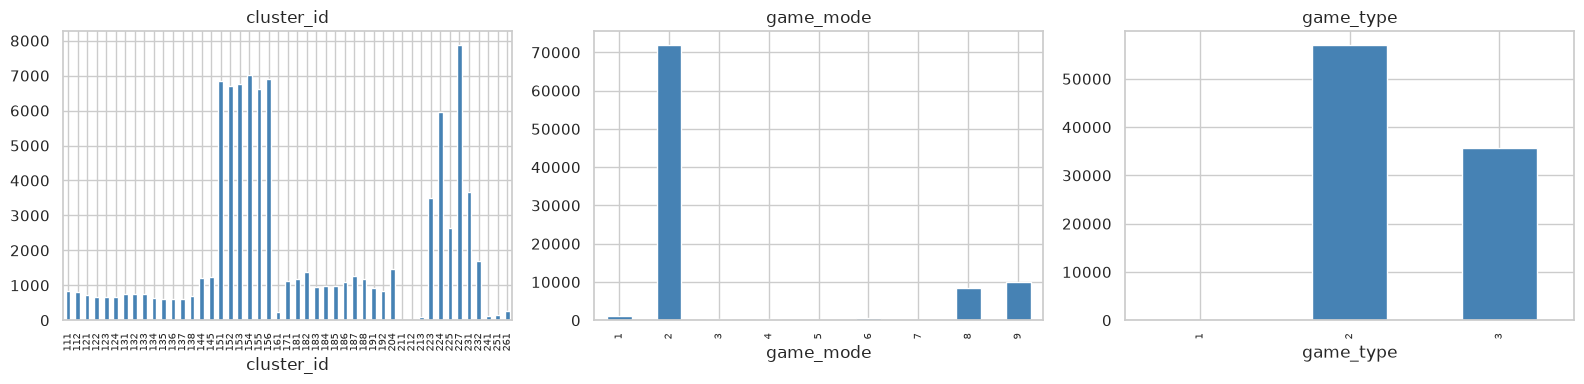

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["cluster_id", "game_mode", "game_type"]):
    X_cls_train[col].value_counts().sort_index().plot.bar(ax=ax, color="steelblue")
    ax.set_title(col)
    ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()

Считаем по обучающей выборке частоту выбора каждого героя и долю побед команды, в которой он был. Это показывает, насколько сильный сигнал несут отдельные герои.

In [6]:
heroes = X_cls_train.filter(like="hero_")
in_team1 = (heroes == 1).to_numpy()
in_team2 = (heroes == -1).to_numpy()
picked = in_team1 | in_team2
hero_stats = pd.DataFrame({
    "pick_rate": picked.mean(axis=0),
    "win_rate": (in_team1 * y_cls_train[:, None] + in_team2 * (1 - y_cls_train)[:, None]).sum(axis=0)
    / np.maximum(picked.sum(axis=0), 1),
}, index=heroes.columns)
print("Героев, которые ни разу не выбирались:", list(hero_stats.index[hero_stats.pick_rate == 0]))
hero_stats = hero_stats[hero_stats.pick_rate > 0]
hero_stats.describe().T

Героев, которые ни разу не выбирались: ['hero_24', 'hero_108']


,count,mean,std,min,25%,50%,75%,max
pick_rate,111.0000,0.0901,0.0701,0.0085,0.0424,0.0706,0.1166,0.3459
win_rate,111.0000,0.4885,0.0444,0.3555,0.4567,0.4939,0.5177,0.6085


Визуализируем популярность героев и связь популярности с процентом побед.

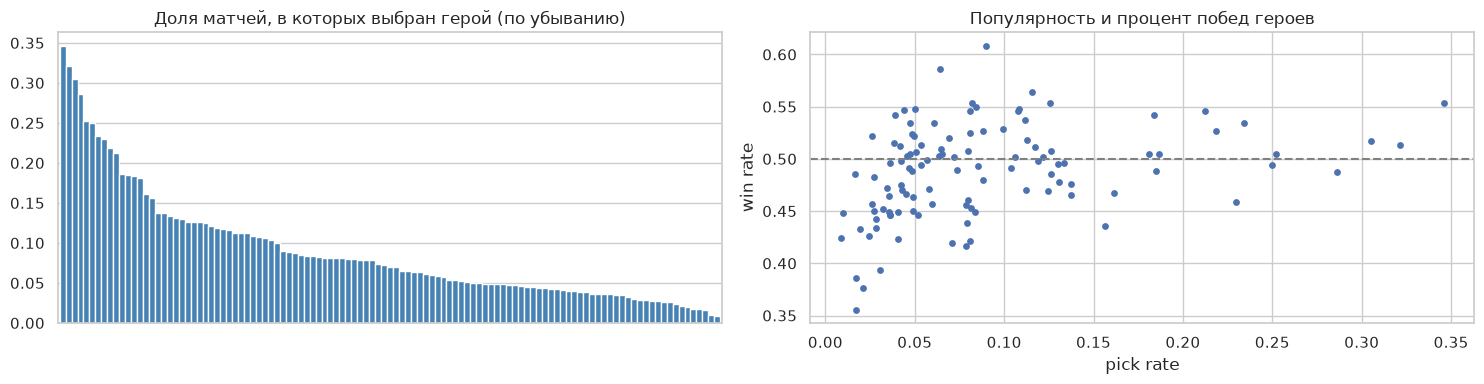

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
hero_stats["pick_rate"].sort_values(ascending=False).plot.bar(ax=axes[0], width=1.0, color="steelblue")
axes[0].set_xticks([])
axes[0].set_title("Доля матчей, в которых выбран герой (по убыванию)")
axes[1].scatter(hero_stats.pick_rate, hero_stats.win_rate, s=15)
axes[1].axhline(0.5, color="grey", ls="--")
axes[1].set_xlabel("pick rate")
axes[1].set_ylabel("win rate")
axes[1].set_title("Популярность и процент побед героев")
plt.tight_layout()

<!-- lab1_eda_cls -->
**Наблюдения по данным Dota 2.**
* Классы почти сбалансированы: команда 1 побеждает в 52.7 % матчей train и 53.4 % матчей test. Константный прогноз «всегда побеждает команда 1» даёт accuracy ≈ 0.53 на test и ROC-AUC = 0.5 — это нижняя граница качества.
* Мета-признаки сильно несбалансированы: 47 серверов (44 % матчей — регион с кодами 15x, 22 % — 22x), режим `game_mode = 2` — 78 % матчей, `game_type` принимает фактически два значения (2 и 3).
* Герои `hero_24` и `hero_108` не встречаются ни разу — это константные признаки.
* Популярность героев различается в 40 раз (pick rate от 0.9 % до 34.6 %), а доля побед — от 36 % до 61 % (медиана 49 %). Отдельные герои несут сигнал, но слабый: большинство win rate лежат в пределах ±5 п. п. от 50 %. Задача трудная — исход определяется прежде всего игрой, а не драфтом, поэтому реалистичный потолок качества — ROC-AUC ≈ 0.6–0.65.

### 1.2. Набор данных для регрессии — Chess (King-Rook vs. King-Pawn), UCI

**Описание.** 3 196 позиций шахматного эндшпиля «король + ладья (белые) против короля + пешки на a7 (чёрные)», ход белых (KRKPA7, UCI id 22). Каждая позиция описана 36 признаками — булевыми утверждениями о позиции, которые сформулировал шахматный эксперт (A. Shapiro) в ходе структурной индукции правил эндшпиля; в UCI признаки даны сокращёнными именами (`bkblk`, `rimmx`, `wknck`, …), их расшифровка приведена в книге Shapiro «Structured Induction in Expert Systems» (1987). Значения — `t/f` (истина/ложь), у `dwipd` — `g/l`, у `wtoeg` — `n/t`, у `katri` — `b/n/w`. Исходная разметка — `won` (белые выигрывают) / `nowin`.

**Постановка как регрессии.** Целевая переменная кодируется числом `1.0` (won) / `0.0` (nowin), и модель предсказывает **непрерывную оценку позиции** ŷ ∈ [0, 1] — оценку шансов белых на выигрыш. Это прямой аналог *оценочной функции* шахматного движка: движок выдаёт не класс, а число, по которому сравнивает и упорядочивает позиции при переборе. Квадратичная ошибка для такой цели — это Brier score, то есть мы учим откалиброванную оценку вероятности выигрыша.

**Практическая задача.** Обучение компактной оценочной функции для эндшпиля вместо хранения полной таблицы эндшпилей (tablebase), подсказки в шахматных тренажёрах, ранжирование позиций при анализе. Набор маленький, полностью детерминированный (разметка получена точным анализом) и логически сложный — на нём хорошо видно, какие модели умеют выучивать нелинейные правила.

Смотрим на сырые признаки шахматного набора.

In [8]:
X_reg_train.head()

,bkblk,bknwy,bkon8,bkona,bkspr,bkxbq,bkxcr,bkxwp,blxwp,bxqsq,...,skrxp,spcop,stlmt,thrsk,wkcti,wkna8,wknck,wkovl,wkpos,wtoeg
785,f,f,f,f,f,t,f,f,f,f,...,f,f,f,f,f,f,t,t,t,n
1901,f,f,f,f,f,f,f,f,f,f,...,f,f,f,f,t,f,f,f,t,n
1360,f,f,f,f,f,t,f,t,t,t,...,f,f,f,f,f,f,f,t,t,n
837,f,f,f,f,f,t,f,f,f,t,...,f,f,f,f,f,f,f,t,t,n
1482,f,f,f,f,f,t,t,t,t,t,...,f,f,f,f,f,f,t,t,t,n


Проверяем распределение целевой переменной и значения признаков: доля выигрышей, число уровней и самое частое значение каждого признака.

In [9]:
print(f"Доля позиций с выигрышем белых: train = {y_reg_train.mean():.3f}, test = {y_reg_test.mean():.3f}")
X_reg_train.describe().T.head(12)

Доля позиций с выигрышем белых: train = 0.522, test = 0.522


,count,unique,top,freq
bkblk,2556,2,f,2260
bknwy,2556,2,f,2375
bkon8,2556,2,f,2455
bkona,2556,2,f,2298
bkspr,2556,2,f,1697
bkxbq,2556,2,f,1373
bkxcr,2556,2,f,1604
bkxwp,2556,2,f,1996
blxwp,2556,2,f,1596
bxqsq,2556,2,f,1776


Кодируем признаки в числа трансформером `ChessFeatures` (бинарные `t/f` → `1/0`, трёхзначный `katri` → one-hot) и смотрим корреляцию каждого признака с целевой переменной.

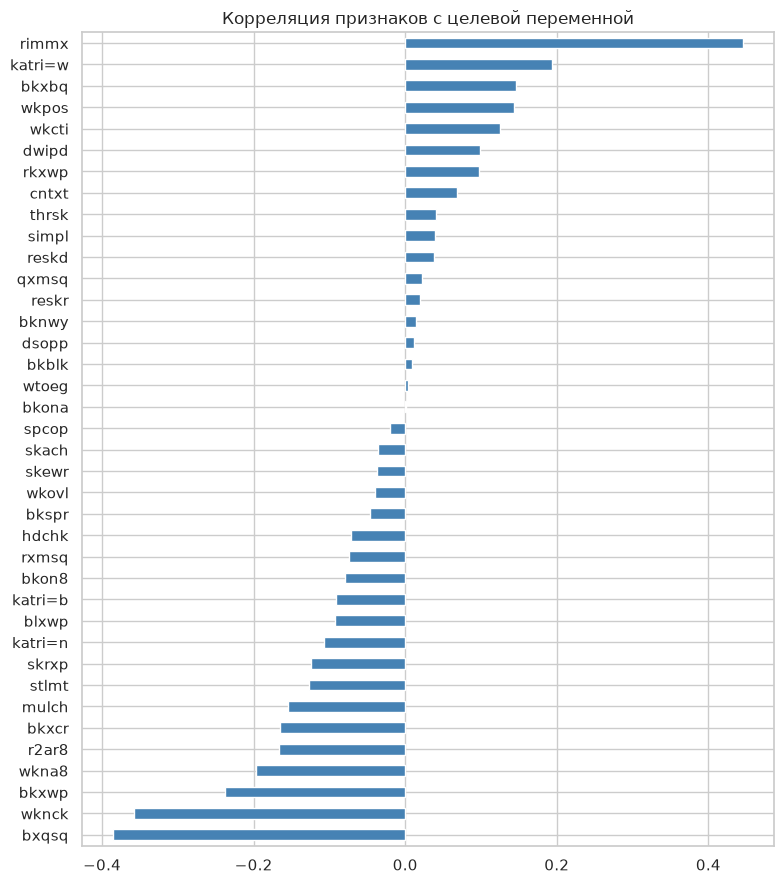

In [10]:
chess_encoder = ChessFeatures().fit(X_reg_train)
chess_encoded = pd.DataFrame(chess_encoder.transform(X_reg_train), columns=chess_encoder.get_feature_names_out())
target_corr = chess_encoded.corrwith(pd.Series(y_reg_train)).sort_values()
target_corr.plot.barh(figsize=(8, 9), color="steelblue", title="Корреляция признаков с целевой переменной")
plt.tight_layout()

<!-- lab1_eda_reg -->
**Наблюдения по данным KRKPA7.**
* Цель сбалансирована: 52.2 % позиций выигрышны для белых (в train и test одинаково благодаря стратификации).
* Признаки почти все бинарные и часто несбалансированные (у многих значение `f` встречается в 80–95 % позиций).
* Сильнее всего с оценкой позиции связаны `rimmx` (r = +0.45), `bxqsq` (−0.39) и `wknck` (−0.36), а у 23 из 38 закодированных признаков |r| < 0.1. При этом набор полностью детерминирован (одинаковые описания всегда имеют одинаковую цель), т. е. исход — точная, но **нелинейная логическая функция** признаков. Для KNN это означает, что слабо коррелированные признаки будут вносить шум в расстояние.

### 1.3. Метрики качества

**Классификация (Dota 2):**
* **ROC-AUC — основная метрика.** Практическая ценность модели — в оценке *вероятности* победы при данном драфте: помощник выбора героев сравнивает вероятности разных вариантов, а не только итоговый класс. ROC-AUC не зависит от порога и показывает, насколько хорошо модель упорядочивает матчи по шансам на победу.
* **Accuracy** — доля правильно предсказанных исходов. Классы почти сбалансированы (≈52.7 / 47.3 %), поэтому accuracy интерпретируема; ориентир — константная модель «всегда побеждает команда 1» с accuracy ≈ 0.53.
* **F1** (для класса «победа команды 1») — баланс точности и полноты, контролирует, что модель не вырождается в предсказание одного класса.

**Регрессия (шахматы):**
* **R² — основная метрика.** Доля объяснённой дисперсии, безразмерна и сравнима между моделями (0 — уровень константы, 1 — идеальная модель).
* **RMSE** — корень из среднеквадратичной ошибки; для цели 0/1 это корень из Brier score, сильно штрафует уверенные ошибки оценки позиции.
* **MAE** — средняя абсолютная ошибка оценки, устойчива к отдельным большим ошибкам и легко интерпретируется.

Дополнительно для каждой модели фиксируем время обучения и предсказания.

## 2. Создание бейзлайна и оценка качества

Бейзлайн — модели `sklearn` с параметрами по умолчанию (`n_neighbors=5`, евклидова метрика, равные веса соседей):
* классификация — `KNeighborsClassifier` на исходных 116 признаках без какой-либо обработки;
* регрессия — `KNeighborsRegressor` поверх минимально необходимого кодирования `ChessFeatures` (категории `t/f` нужно превратить в числа).

Функция `evaluate` обучает модель на train, считает метрики на test и замеряет время.

In [11]:
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

baseline_cls = KNeighborsClassifier()
baseline_reg = make_pipeline(ChessFeatures(), KNeighborsRegressor())

log.add("classification", "sklearn baseline",
        evaluate(baseline_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "sklearn baseline",
        evaluate(baseline_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification"), log.table("regression"))

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.5273,0.5278,0.5640,0.0782,11.7533


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.8269,0.2078,0.1172,0.0067,0.1769


<!-- lab1_baseline -->
**Вывод по бейзлайну.**
* *Классификация:* KNN с k=5 на сырых признаках практически не работает: ROC-AUC = 0.527, accuracy = 0.528 — **хуже константного прогноза** (0.535 на test). При этом предсказание для 10 тыс. матчей занимает ≈12 с: KNN «ленивый» и считает расстояния до всех 92 тыс. обучающих объектов.
* *Регрессия:* на шахматах KNN работает заметно лучше — R² = 0.827, MAE = 0.117: похожие по описанию позиции обычно имеют одинаковую оценку.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

**Классификация (Dota 2):**
* **H1. Масштабирование признаков.** `cluster_id` (значения 111–261) доминирует в евклидовом расстоянии над признаками героев (−1/0/1) — стандартизация должна сделать расстояние осмысленным.
* **H2. Обработка мета-признаков.** Коды сервера/режима — категориальные, их числовая близость ничего не значит. Проверим удаление мета-признаков и one-hot кодирование, а также удаление двух героев, которые ни разу не выбирались.
* **H3. Число соседей.** Сигнал в данных слабый и шумный, при k=5 оценка вероятности очень грубая (всего 6 возможных значений) — увеличение k должно сгладить её.
* **H4. Новые признаки.** Вместо 113 разреженных индикаторов героев описать матч компактно: суммарный win rate героев каждой команды, синергия пар героев внутри команды и «контрпики» между командами (`DotaFeatures(synergy=True)`; статистики считаются только по обучающим фолдам, для train — out-of-fold, чтобы не было утечки целевой переменной).
* **H5. Подбор гиперпараметров** (`n_neighbors`, `weights`) на кросс-валидации.

**Регрессия (шахматы):**
* **H1. Масштабирование.** Признаки бинарные; стандартизация увеличит вес редких признаков — проверим, полезно ли это.
* **H2. Метрика расстояния**: евклидова, манхэттенская, косинусная.
* **H3. Отбор признаков.** Многие признаки слабо связаны с целью (см. п. 1.2), а KNN чувствителен к нерелевантным признакам — оставим k лучших по F-статистике.
* **H4. Взвешивание признаков по важности.** Вместо жёсткого отбора — умножить каждый признак на его важность (feature importance случайного леса), чтобы расстояние учитывало в первую очередь значимые признаки.
* **H5. Подбор гиперпараметров** (`n_neighbors`, `weights`, степень весов) на кросс-валидации.

### 3.2. Проверка гипотез для классификации

**H1.** Сравниваем на 5-кратной кросс-валидации KNN на сырых признаках и KNN после `StandardScaler`. `compare_cv` возвращает средний и стандартное отклонение ROC-AUC на валидации, а также ROC-AUC на обучающих фолдах (для контроля переобучения).

In [12]:
h1_cls = compare_cv({
    "сырые признаки": KNeighborsClassifier(),
    "StandardScaler": make_pipeline(StandardScaler(), KNeighborsClassifier()),
}, X_cls_train, y_cls_train, cv_cls, "roc_auc")
h1_cls

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
сырые признаки,0.5303,0.0025,0.7628,0.1620
StandardScaler,0.5316,0.0034,0.7658,0.3119


<!-- lab1_h1_cls -->
**H1 подтверждена слабо.** Стандартизация повышает ROC-AUC на CV с 0.5303 до 0.5316 — в пределах разброса по фолдам (≈0.003). Основная проблема не в масштабе: ROC-AUC на обучающих фолдах ≈ 0.77 против 0.53 на валидации — модель с k=5 сильно переобучена. Стандартизацию оставляем.

**H2.** Сравниваем варианты обработки мета-признаков (все варианты — со стандартизацией).

In [13]:
h2_cls = compare_cv({
    "мета как числа": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "без мета-признаков": make_pipeline(DotaFeatures(meta="drop", drop_constant=True), StandardScaler(),
                                        KNeighborsClassifier()),
    "мета one-hot": make_pipeline(DotaFeatures(meta="onehot", drop_constant=True), StandardScaler(),
                                  KNeighborsClassifier()),
}, X_cls_train, y_cls_train, cv_cls, "roc_auc")
h2_cls

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
мета как числа,0.5316,0.0034,0.7658,0.2326
без мета-признаков,0.5322,0.0027,0.7656,0.2091
мета one-hot,0.5281,0.0014,0.7642,0.5243


<!-- lab1_h2_cls -->
**H2 не подтверждена.** Удаление мета-признаков даёт +0.0006 (в пределах шума), а one-hot кодирование ухудшает качество (0.5281): 50+ дополнительных бинарных признаков добавляют в расстояние шум, не связанный с исходом. Мета-признаки удаляем — это упрощает модель без потери качества.

**H3.** Строим зависимость ROC-AUC на кросс-валидации от числа соседей для представления «герои без мета-признаков».

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
5,0.5322,0.0027,0.7656,0.1988
25,0.5578,0.0021,0.6571,0.1894
101,0.5862,0.0010,0.6291,0.2009
301,0.6044,0.0025,0.6255,0.1968
701,0.6171,0.0027,0.6286,0.3654


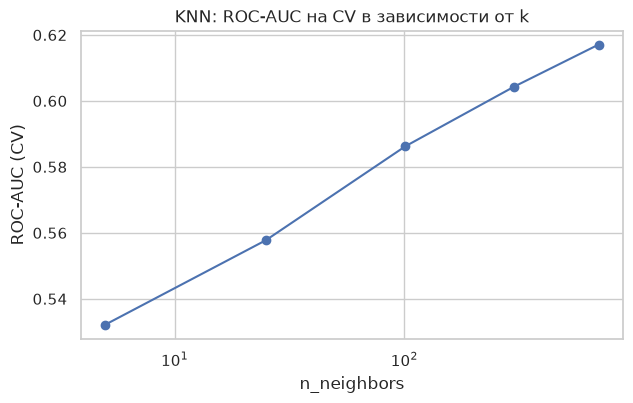

In [14]:
k_values = [5, 25, 101, 301, 701]
h3_cls = compare_cv({
    k: make_pipeline(DotaFeatures(meta="drop", drop_constant=True), StandardScaler(), KNeighborsClassifier(k))
    for k in k_values
}, X_cls_train, y_cls_train, cv_cls, "roc_auc")
ax = h3_cls["cv_mean"].plot(marker="o", logx=True, figsize=(7, 4), title="KNN: ROC-AUC на CV в зависимости от k")
ax.set_xlabel("n_neighbors")
ax.set_ylabel("ROC-AUC (CV)")
h3_cls

<!-- lab1_h3_cls -->
**H3 подтверждена.** Рост числа соседей монотонно улучшает ROC-AUC на CV: 0.532 (k=5) → 0.586 (k=101) → 0.617 (k=701), а разрыв между train и CV сокращается с 0.23 до 0.01. При слабом сигнале усреднение по сотням соседей даёт гораздо более точную оценку вероятности победы.

**H4.** Сравниваем три представления матча при k=301: только индикаторы героев, индикаторы + статистики героев, и только 7 компактных статистик (win rate, синергия, контрпики).

In [15]:
h4_cls = compare_cv({
    "индикаторы героев": make_pipeline(DotaFeatures(meta="drop", drop_constant=True), StandardScaler(),
                                       KNeighborsClassifier(301)),
    "индикаторы + статистики": make_pipeline(DotaFeatures(meta="drop", drop_constant=True, synergy=True),
                                             StandardScaler(), KNeighborsClassifier(301)),
    "только статистики (7 признаков)": make_pipeline(DotaFeatures(meta="drop", heroes="none", synergy=True),
                                                     StandardScaler(), KNeighborsClassifier(301)),
}, X_cls_train, y_cls_train, cv_cls, "roc_auc")
h4_cls

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
индикаторы героев,0.6044,0.0025,0.6255,0.5976
индикаторы + статистики,0.6268,0.0022,0.6675,8.2258
только статистики (7 признаков),0.6348,0.0038,0.6797,7.6913


<!-- lab1_h4_cls -->
**H4 подтверждена.** При одинаковом k=301 компактное представление из 7 статистик драфта даёт ROC-AUC = 0.635 против 0.604 у индикаторов героев. Добавление статистик к индикаторам помогает меньше (0.627): в 111-мерном пространстве индикаторов расстояние определяется в основном совпадением конкретных героев, а не силой составов, и статистики «тонут» среди остальных признаков. Все 7 новых признаков заметно коррелируют с исходом (r = 0.15–0.24), тогда как отдельные индикаторы героев — на порядок слабее.

Посмотрим, какие признаки получаются в компактном представлении и насколько они связаны с исходом матча.

In [16]:
dota_features = DotaFeatures(meta="drop", heroes="none", synergy=True)
dota_compact = pd.DataFrame(dota_features.fit_transform(X_cls_train, y_cls_train),
                            columns=dota_features.get_feature_names_out())
dota_compact.assign(team1_win=y_cls_train).corr()["team1_win"].drop("team1_win").to_frame("корреляция с целью")

,корреляция с целью
wr_team1,0.1711
wr_team2,-0.1685
wr_diff,0.2352
syn_team1,0.1578
syn_team2,-0.1521
syn_diff,0.2149
counter,0.2313


**H5.** Подбираем `n_neighbors` и `weights` поиском по сетке на кросс-валидации для лучшего представления. Признаки считаются внутри `Pipeline`, поэтому на каждом фолде статистики героев оцениваются только по обучающей части.

In [17]:
pipe_cls = Pipeline([
    ("features", DotaFeatures(meta="drop", heroes="none", synergy=True)),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier()),
], memory=memory)
search_cls = GridSearchCV(pipe_cls, {
    "model__n_neighbors": [101, 301, 701, 1001, 1501],
    "model__weights": ["uniform", "distance"],
}, cv=cv_cls, scoring="roc_auc", n_jobs=5).fit(X_cls_train, y_cls_train)
print("Лучшие параметры:", search_cls.best_params_)
cv_report(search_cls)

Лучшие параметры: {'model__n_neighbors': 1501, 'model__weights': 'distance'}


,model__n_neighbors,model__weights,mean_test_score,std_test_score,rank_test_score
0,1501,distance,0.6373,0.0039,1
1,1501,uniform,0.6372,0.0039,2
2,1001,distance,0.6370,0.0039,3
3,1001,uniform,0.6370,0.0039,4
4,701,uniform,0.6369,0.0039,5
5,701,distance,0.6368,0.0038,6
6,301,uniform,0.6348,0.0038,7
7,301,distance,0.6346,0.0037,8
8,101,uniform,0.6283,0.0037,9
9,101,distance,0.6279,0.0037,10


<!-- lab1_h5_cls -->
**H5.** Лучший результат на CV — `n_neighbors = 1501`, `weights = "distance"` (ROC-AUC = 0.6373). Начиная с k ≈ 700 качество выходит на плато (0.6368–0.6373, различия в 10 раз меньше разброса по фолдам 0.004), а тип весов почти не важен — среди сотен соседей расстояния близки. Оптимум оказался на границе сетки, но рост от k=701 до k=1501 составляет лишь 0.0004, так что расширять сетку бессмысленно (при k → n KNN вырождается в константу).

### 3.3. Проверка гипотез для регрессии

**H1 и H2.** Сравниваем масштабирование и разные метрики расстояния (k=5, как в бейзлайне). Метрика — R² на 5-кратной кросс-валидации.

In [18]:
h12_reg = compare_cv({
    "евклидова (бейзлайн)": make_pipeline(ChessFeatures(), KNeighborsRegressor()),
    "StandardScaler + евклидова": make_pipeline(ChessFeatures(), StandardScaler(), KNeighborsRegressor()),
    "манхэттенская": make_pipeline(ChessFeatures(), KNeighborsRegressor(metric="manhattan")),
    "косинусная": make_pipeline(ChessFeatures(), KNeighborsRegressor(metric="cosine")),
}, X_reg_train, y_reg_train, cv_reg, "r2")
h12_reg

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
евклидова (бейзлайн),0.7794,0.0167,0.8596,0.0248
StandardScaler + евклидова,0.7348,0.0195,0.8406,0.0268
манхэттенская,0.7794,0.0167,0.8596,0.0226
косинусная,0.7876,0.0167,0.8606,0.0203


<!-- lab1_h12_reg -->
**H1 не подтверждена, H2 — частично.**
* Стандартизация **ухудшает** качество (R² 0.779 → 0.735): после неё редкие бинарные признаки получают больший вес в расстоянии, хотя важнее они не становятся.
* Манхэттенская метрика даёт ровно тот же результат, что и евклидова: для векторов из 0/1 квадрат евклидова расстояния равен расстоянию Хэмминга, поэтому порядок соседей одинаков. Косинусная метрика чуть лучше (0.788, +0.008), но в пределах разброса (0.017).

**H3.** Отбор k лучших признаков по F-статистике (`SelectKBest(f_regression)`) — строим зависимость R² от числа оставленных признаков.

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
5,0.6907,0.1072,0.6847,0.0176
10,0.8028,0.0355,0.8229,0.0162
12,0.8333,0.0270,0.8486,0.0162
15,0.8456,0.0223,0.8817,0.0163
17,0.8526,0.0213,0.8928,0.0161
20,0.8325,0.0199,0.8858,0.0134
25,0.8200,0.0131,0.8790,0.0146
30,0.7823,0.0182,0.8593,0.0157
38,0.7794,0.0167,0.8596,0.0156


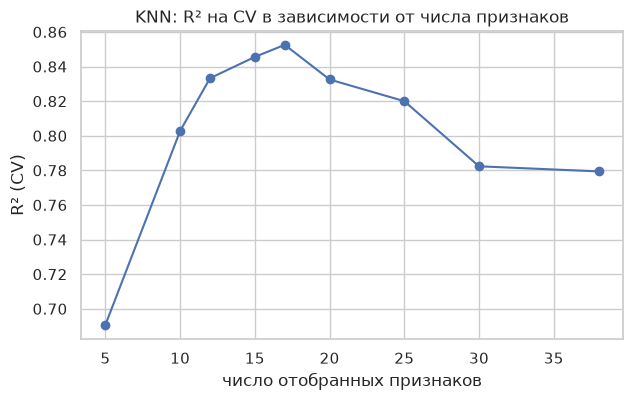

In [19]:
from sklearn.feature_selection import SelectKBest, f_regression

h3_reg = compare_cv({
    k: make_pipeline(ChessFeatures(), SelectKBest(f_regression, k=k), KNeighborsRegressor())
    for k in [5, 10, 12, 15, 17, 20, 25, 30, 38]
}, X_reg_train, y_reg_train, cv_reg, "r2")
ax = h3_reg["cv_mean"].plot(marker="o", figsize=(7, 4), title="KNN: R² на CV в зависимости от числа признаков")
ax.set_xlabel("число отобранных признаков")
ax.set_ylabel("R² (CV)")
h3_reg

<!-- lab1_h3_reg -->
**H3 подтверждена.** Отбор признаков по F-статистике повышает R² на CV с 0.779 (все 38 признаков) до 0.853 (17 лучших признаков); при слишком сильном отборе (5 признаков) теряется нужная информация (0.691) и резко растёт разброс по фолдам.

**H4.** Взвешивание признаков: трансформер `ImportanceWeighter` обучает случайный лес на обучающем фолде и умножает каждый признак на нормированную важность (в степени `power`). Сравниваем с лучшим вариантом отбора признаков.

In [20]:
from mllab.features import ImportanceWeighter

h4_reg = compare_cv({
    "отбор 15 признаков": make_pipeline(ChessFeatures(), SelectKBest(f_regression, k=15), KNeighborsRegressor()),
    "веса = важность RF": make_pipeline(ChessFeatures(), ImportanceWeighter(), KNeighborsRegressor()),
}, X_reg_train, y_reg_train, cv_reg, "r2", n_jobs=1)
h4_reg

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
отбор 15 признаков,0.8456,0.0223,0.8817,0.0111
веса = важность RF,0.9533,0.0075,0.9750,0.5034


<!-- lab1_h4_reg -->
**H4 подтверждена — это главный источник улучшения.** Взвешивание признаков по важности случайного леса даёт R² = 0.953 против 0.846 у жёсткого отбора 15 признаков. Причины: (1) «мягкие» веса сохраняют информацию слабых признаков, но не дают им зашумлять расстояние; (2) важность в лесу учитывает нелинейные взаимодействия, а F-статистика — только линейную корреляцию отдельного признака с целью. На графике видно, что наибольший вес получают те же `rimmx`, `bxqsq`, `wknck`, что лидировали по корреляции, но порядок остальных признаков другой.

Визуализируем, какие признаки получают наибольший вес — это и есть «важные» с точки зрения правил эндшпиля.

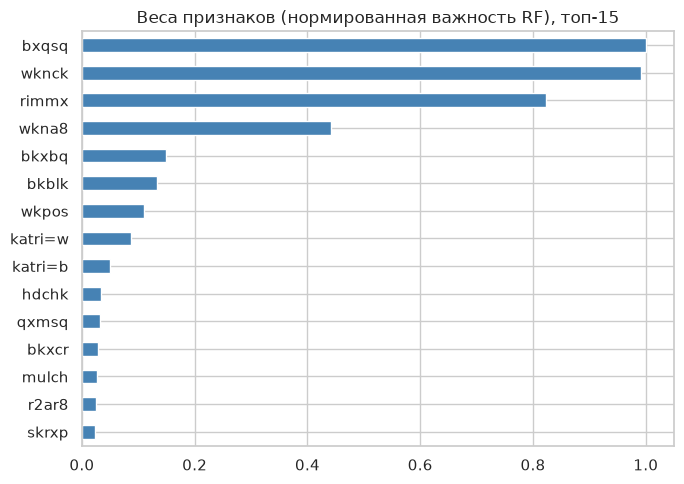

In [21]:
weighter = ImportanceWeighter().fit(chess_encoded, y_reg_train)
pd.Series(weighter.weights_, index=chess_encoded.columns).sort_values().tail(15).plot.barh(
    figsize=(7, 5), color="steelblue", title="Веса признаков (нормированная важность RF), топ-15")
plt.tight_layout()

**H5.** Подбираем `n_neighbors`, `weights` и степень весов признаков поиском по сетке.

In [22]:
pipe_reg = Pipeline([
    ("features", ChessFeatures()),
    ("weighter", ImportanceWeighter()),
    ("model", KNeighborsRegressor()),
], memory=memory)
search_reg = GridSearchCV(pipe_reg, {
    "weighter__power": [0.5, 1.0, 2.0],
    "model__n_neighbors": [1, 3, 5, 7, 10, 15],
    "model__weights": ["uniform", "distance"],
}, cv=cv_reg, scoring="r2", n_jobs=4).fit(X_reg_train, y_reg_train)
print("Лучшие параметры:", search_reg.best_params_)
cv_report(search_reg)

Лучшие параметры: {'model__n_neighbors': 3, 'model__weights': 'distance', 'weighter__power': 1.0}


,model__n_neighbors,model__weights,weighter__power,mean_test_score,std_test_score,rank_test_score
0,3,distance,1.0000,0.9672,0.0076,1
1,3,distance,2.0000,0.9666,0.0073,2
2,3,distance,0.5000,0.9648,0.0071,3
3,5,distance,2.0000,0.9642,0.0064,4
4,3,uniform,1.0000,0.9632,0.0091,5
5,7,distance,2.0000,0.9629,0.0048,6
6,5,distance,1.0000,0.9622,0.0068,7
7,3,uniform,2.0000,0.9621,0.0090,8
8,10,distance,2.0000,0.9617,0.0050,9
9,5,distance,0.5000,0.9617,0.0061,10


<!-- lab1_h5_reg -->
**H5.** Лучшая конфигурация — `n_neighbors = 3`, `weights = "distance"`, веса признаков в степени 1 (R² на CV = 0.967). После взвешивания пространство стало осмысленным, и ближайшие позиции действительно похожи, поэтому выгодно малое k; данные без шума разметки, поэтому сильное усреднение не нужно.

### 3.4. Улучшенный бейзлайн

По результатам проверки гипотез формируем улучшенный бейзлайн:
* **классификация** — компактные признаки драфта (win rate, синергия, контрпики) → `StandardScaler` → `KNeighborsClassifier` с подобранными `n_neighbors` и `weights`;
* **регрессия** — кодирование `ChessFeatures` → взвешивание признаков по важности → `KNeighborsRegressor` с подобранными параметрами.

Обучаем обе модели на всём train с лучшими параметрами и оцениваем на test.

In [23]:
from sklearn.base import clone

improved_cls = clone(search_cls.best_estimator_)
improved_reg = clone(search_reg.best_estimator_)

log.add("classification", "sklearn improved",
        evaluate(improved_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "sklearn improved",
        evaluate(improved_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification"), log.table("regression"))

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.5273,0.5278,0.5640,0.0782,11.7533
sklearn improved,0.6384,0.5974,0.6353,0.1685,7.0899


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.8269,0.2078,0.1172,0.0067,0.1769
sklearn improved,0.9829,0.0652,0.0063,0.1096,0.1117


<!-- lab1_improved -->
**Сравнение улучшенного бейзлайна с бейзлайном (test).**
* *Классификация:* ROC-AUC 0.527 → **0.638** (+0.111), accuracy 0.528 → 0.597, F1 0.564 → 0.635. Модель стала заметно лучше константы, а предсказание — быстрее (7.1 с против 11.8 с) за счёт 7 признаков вместо 116.
* *Регрессия:* R² 0.827 → **0.983**, RMSE 0.208 → 0.065, MAE 0.117 → 0.006 (в 19 раз меньше): взвешенный KNN почти безошибочно оценивает позиции эндшпиля.

Улучшения в обеих задачах получены прежде всего за счёт **представления данных** (признаки драфта, взвешивание признаков), а не подбора гиперпараметров: для метрического метода качество определяется тем, насколько расстояние отражает сходство объектов по смыслу задачи.

## 4. Имплементация алгоритма машинного обучения

### 4.1. Собственная реализация KNN

Реализация находится в `mllab/knn.py` (только `numpy`, от `sklearn` используются лишь базовые классы `BaseEstimator`/`ClassifierMixin` для совместимости с `Pipeline` и `GridSearchCV`):
* `fit` просто запоминает обучающую выборку (KNN — «ленивый» алгоритм);
* расстояния считаются блоками по `batch_size` строк, чтобы не держать в памяти матрицу 10 000 × 92 650: евклидово — через разложение ‖a−b‖² = ‖a‖² − 2·a·b + ‖b‖² (одно матричное умножение), манхэттенское — по признакам, косинусное — через нормированные векторы;
* k ближайших соседей находятся `np.argpartition` (O(n) вместо полной сортировки), затем упорядочиваются;
* классификатор возвращает долю (или взвешенную долю) соседей каждого класса, регрессор — (взвешенное) среднее целевой переменной; при `weights="distance"` вес соседа равен 1/d, а при нулевом расстоянии учитываются только совпадающие объекты (как в `sklearn`).

Выводим исходный код реализации прямо в ноутбук.

In [24]:
display(Code(inspect.getsource(mllab.knn), language="python"))

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin


def _pairwise_distances(A, B, metric, B_sq=None):
    if metric == "euclidean":
        A_sq = np.einsum("ij,ij->i", A, A)
        if B_sq is None:
            B_sq = np.einsum("ij,ij->i", B, B)
        sq = A_sq[:, None] - 2.0 * (A @ B.T) + B_sq[None, :]
        return np.sqrt(np.maximum(sq, 0.0))
    if metric == "manhattan":
        out = np.zeros((A.shape[0], B.shape[0]))
        for j in range(A.shape[1]):
            out += np.abs(A[:, j, None] - B[None, :, j])
        return out
    if metric == "cosine":
        A_norm = A / np.maximum(np.linalg.norm(A, axis=1, keepdims=True), 1e-12)
        B_norm = B / np.maximum(np.linalg.norm(B, axis=1, keepdims=True), 1e-12)
        return np.maximum(1.0 - A_norm @ B_norm.T, 0.0)
    raise ValueError(f"unknown metric: {metric}")


class _KNNBase(BaseEstimator):
    def __init__(self, n_neighbors=5, weights="uniform", metric="euclidean", batch_size=512):
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.metric = metric
        self.batch_size = batch_size

    def _store(self, X, y):
        self.X_ = np.asarray(X, dtype=float)
        self.y_ = np.asarray(y)
        self.X_sq_ = np.einsum("ij,ij->i", self.X_, self.X_)
        self.n_features_in_ = self.X_.shape[1]

    def kneighbors(self, X):
        X = np.asarray(X, dtype=float)
        k = min(self.n_neighbors, len(self.X_))
        dist = np.empty((len(X), k))
        idx = np.empty((len(X), k), dtype=int)
        for start in range(0, len(X), self.batch_size):
            stop = start + self.batch_size
            D = _pairwise_distances(X[start:stop], self.X_, self.metric, self.X_sq_)
            part = np.argpartition(D, k - 1, axis=1)[:, :k]
            part_d = np.take_along_axis(D, part, axis=1)
            order = np.argsort(part_d, axis=1, kind="stable")
            idx[start:stop] = np.take_along_axis(part, order, axis=1)
            dist[start:stop] = np.take_along_axis(part_d, order, axis=1)
        return dist, idx

    def _neighbor_weights(self, dist):
        if self.weights == "uniform":
            return np.ones_like(dist)
        if self.weights == "distance":
            zero = dist <= 1e-12
            with np.errstate(divide="ignore"):
                w = 1.0 / dist
            has_zero = zero.any(axis=1)
            w[has_zero] = zero[has_zero].astype(float)
            return w
        raise ValueError(f"unknown weights: {self.weights}")


class KNNClassifier(_KNNBase, ClassifierMixin):
    def fit(self, X, y):
        self.classes_, encoded = np.unique(y, return_inverse=True)
        self._store(X, encoded)
        return self

    def predict_proba(self, X):
        dist, idx = self.kneighbors(X)
        w = self._neighbor_weights(dist)
        labels = self.y_[idx]
        proba = np.zeros((len(idx), len(self.classes_)))
        for c in range(len(self.classes_)):
            proba[:, c] = (w * (labels == c)).sum(axis=1)
        return proba / proba.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


class KNNRegressor(_KNNBase, RegressorMixin):
    def fit(self, X, y):
        self._store(X, np.asarray(y, dtype=float))
        return self

    def predict(self, X):
        dist, idx = self.kneighbors(X)
        w = self._neighbor_weights(dist)
        return (w * self.y_[idx]).sum(axis=1) / w.sum(axis=1)

Обучаем собственные модели с параметрами бейзлайна (k=5, евклидова метрика, равные веса) на тех же данных и оцениваем на test.

In [25]:
custom_cls = mllab.KNNClassifier(n_neighbors=5)
custom_reg = make_pipeline(ChessFeatures(), mllab.KNNRegressor(n_neighbors=5))

log.add("classification", "custom",
        evaluate(custom_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "custom",
        evaluate(custom_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification").loc[["sklearn baseline", "custom"]],
        log.table("regression").loc[["sklearn baseline", "custom"]])

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.5273,0.5278,0.5640,0.0782,11.7533
custom,0.5273,0.5278,0.5640,0.0663,16.5556


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.8269,0.2078,0.1172,0.0067,0.1769
custom,0.8161,0.2142,0.1219,0.0059,0.0407


Проверим, откуда берутся расхождения: сравним долю объектов, у которых предсказания `sklearn` и собственной реализации совпадают, и посмотрим, как часто у k-го и (k+1)-го соседа одинаковое расстояние (равенство расстояний делает выбор соседей неоднозначным).

In [26]:
reg_features = ChessFeatures().fit(X_reg_train)
A_train, A_test = reg_features.transform(X_reg_train), reg_features.transform(X_reg_test)
sk_pred = KNeighborsRegressor().fit(A_train, y_reg_train).predict(A_test)
my_model = mllab.KNNRegressor(n_neighbors=6).fit(A_train, y_reg_train)
my_pred = mllab.KNNRegressor().fit(A_train, y_reg_train).predict(A_test)
dist, _ = my_model.kneighbors(A_test)
print(f"Совпадающих предсказаний (регрессия): {np.mean(np.isclose(sk_pred, my_pred)):.3f}")
print(f"Доля объектов, где 5-й и 6-й соседи равноудалены: {np.mean(np.isclose(dist[:, 4], dist[:, 5])):.3f}")

Совпадающих предсказаний (регрессия): 0.750
Доля объектов, где 5-й и 6-й соседи равноудалены: 0.820


<!-- lab1_custom -->
**Вывод по собственной реализации.**
* *Классификация:* метрики собственного KNN **полностью совпадают** с `sklearn` (ROC-AUC 0.5273, accuracy 0.5278, F1 0.5640). Предсказание медленнее (16.6 с против 11.8 с): `sklearn` считает расстояния многопоточно в оптимизированном Cython-коде.
* *Регрессия:* R² 0.816 против 0.827. Расхождение вызвано не ошибкой, а **равенством расстояний**: признаки бинарные, расстояние принимает лишь несколько значений (√h, где h — число различающихся признаков), и у 82 % тестовых позиций 5-й и 6-й соседи равноудалены. Какой из равноудалённых соседей попадёт в пятёрку, зависит от порядка обхода (`argpartition` против алгоритма `sklearn`), поэтому совпадают 75 % предсказаний. На шахматах собственная реализация быстрее (0.04 с против 0.18 с) — на маленьких данных накладные расходы `sklearn` больше.

### 4.2. Собственная реализация + техники улучшенного бейзлайна

Добавляем к собственным моделям все техники из п. 3.4: те же признаки, масштабирование/взвешивание и подобранные гиперпараметры. Для взвешивания признаков в регрессии важности считаются **собственным** случайным лесом `mllab.RandomForestRegressor` (реализация из ЛР №4), чтобы весь конвейер, кроме кодирования признаков, был самописным.

In [27]:
best_cls = search_cls.best_params_
best_reg = search_reg.best_params_

custom_improved_cls = Pipeline([
    ("features", DotaFeatures(meta="drop", heroes="none", synergy=True)),
    ("scaler", StandardScaler()),
    ("model", mllab.KNNClassifier(n_neighbors=best_cls["model__n_neighbors"],
                                  weights=best_cls["model__weights"])),
], memory=memory)
custom_improved_reg = Pipeline([
    ("features", ChessFeatures()),
    ("weighter", ImportanceWeighter(
        estimator=mllab.RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        power=best_reg["weighter__power"])),
    ("model", mllab.KNNRegressor(n_neighbors=best_reg["model__n_neighbors"], weights=best_reg["model__weights"])),
])

log.add("classification", "custom improved",
        evaluate(custom_improved_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "custom improved",
        evaluate(custom_improved_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification").loc[["sklearn improved", "custom improved"]],
        log.table("regression").loc[["sklearn improved", "custom improved"]])

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn improved,0.6384,0.5974,0.6353,0.1685,7.0899
custom improved,0.6384,0.5974,0.6353,0.2429,17.6113


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn improved,0.9829,0.0652,0.0063,0.1096,0.1117
custom improved,0.9830,0.0651,0.0062,6.3572,0.1062


<!-- lab1_custom_improved -->
**Вывод.** С техниками улучшенного бейзлайна собственный KNN даёт **те же результаты**, что и `sklearn`: в классификации метрики совпадают точно (ROC-AUC 0.6384 — на непрерывных признаках равных расстояний нет), в регрессии — R² 0.9830 против 0.9829 (веса признаков считаются собственным случайным лесом и немного отличаются). Относительно собственного бейзлайна (п. 4.1) прирост такой же, как у `sklearn`: +0.111 ROC-AUC и +0.167 R². Обучение регрессора дольше (6.4 с) из-за обучения собственного леса для весов, а предсказание классификатора с k=1501 — в 2.5 раза медленнее, чем в `sklearn`.

## 5. Итоги лабораторной работы

Сводная таблица всех четырёх вариантов для обеих задач; результаты сохраняются в `results/lab1.json` для итогового сравнения алгоритмов.

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.5273,0.5278,0.5640,0.0782,11.7533
sklearn improved,0.6384,0.5974,0.6353,0.1685,7.0899
custom,0.5273,0.5278,0.5640,0.0663,16.5556
custom improved,0.6384,0.5974,0.6353,0.2429,17.6113


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.8269,0.2078,0.1172,0.0067,0.1769
sklearn improved,0.9829,0.0652,0.0063,0.1096,0.1117
custom,0.8161,0.2142,0.1219,0.0059,0.0407
custom improved,0.9830,0.0651,0.0062,6.3572,0.1062


Сохранено: results/lab1.json


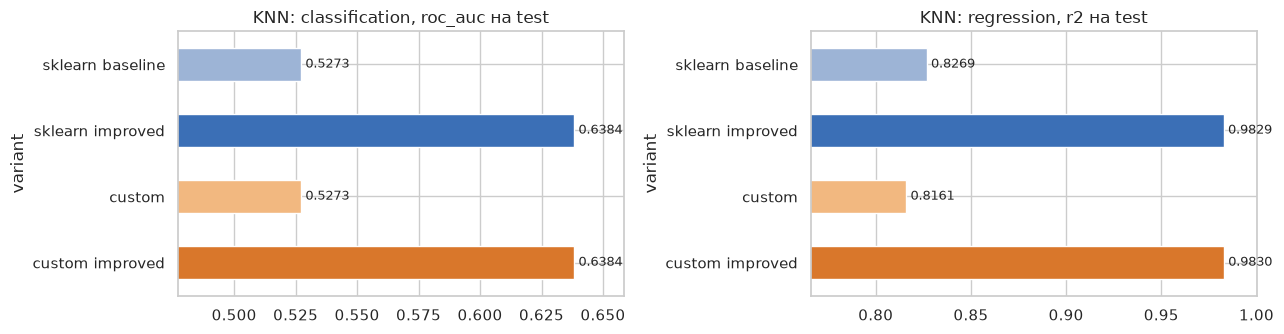

In [28]:
display(log.table("classification"), log.table("regression"))
log.plot()
print("Сохранено:", log.save().relative_to(ROOT))

<!-- lab1_summary -->
**Выводы по ЛР №1.**
1. KNN «из коробки» не справляется с Dota 2 (хуже константы), но неплохо работает на шахматах (R² 0.83) — качество KNN целиком определяется тем, насколько евклидово расстояние в исходных признаках отражает сходство объектов.
2. Главные улучшения дала работа с признаковым пространством: компактные статистики драфта (+0.03 ROC-AUC при равном k) и взвешивание признаков по важности (+0.11 R² на CV). Подбор k важен для шумной классификации (k ≈ 1000), а для детерминированной регрессии оптимально малое k = 3.
3. Масштабирование помогает только при признаках разного масштаба (Dota) и вредит на однородных бинарных признаках (шахматы).
4. Собственная реализация KNN совпадает с `sklearn` с точностью до выбора среди равноудалённых соседей и даёт такие же улучшения от тех же техник; по скорости на больших данных она уступает оптимизированному `sklearn`.